In [1]:
# سلول ۱: Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      RandomizedSearchCV, cross_val_score, cross_val_predict)
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               ExtraTreesClassifier, HistGradientBoostingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, classification_report, confusion_matrix)
import joblib

RANDOM_STATE = 42
print('\u2705 Libraries imported')


✅ Libraries imported


## گام ۱: ثابت‌های شیمیایی — پتانسیل احیای استاندارد (۲۳ فلز)
با دقیق‌تر شدن نام فلزات در دیتاست، فلزات جدیدی (Ba, Bi, Ca, Cd, Ce, Cr, Li, Pb) ظاهر شدن که در نسخه قبلی پوشش داده نشده بودن. پتانسیل احیای استاندارد این‌ها هم اضافه شد.


In [2]:
# سلول ۲: جدول پتانسیل احیا (۲۳ فلز) + تابع پارس نام فلزات
REDUCTION_POTENTIAL = {
    'Ag': 0.80, 'Au': 1.50, 'Cu': 0.34, 'Fe': -0.44, 'Zn': -0.76, 'Pd': 0.95,
    'Pt': 1.18, 'Ni': -0.25, 'Co': -0.28, 'Mg': -2.37, 'Mn': -1.18, 'Ru': 0.60,
    'Se': 0.74, 'Sn': -0.14, 'Ti': -1.63,
    'Ba': -2.91, 'Bi': 0.32, 'Ca': -2.87, 'Cd': -0.40, 'Ce': -2.34, 'Cr': -0.74,
    'Li': -3.04, 'Pb': -0.13,
}
METALS_TO_FLAG = list(REDUCTION_POTENTIAL.keys())

def parse_metal_pair(bimetallic_str):
    s = str(bimetallic_str)
    parts = s.split('-')
    m1 = parts[0] if len(parts) > 0 else None
    m2 = parts[1] if len(parts) > 1 else None
    is_oxide = False
    clean = []
    for m in [m1, m2]:
        if m is None or m == 'based':
            clean.append(None)
        elif m not in REDUCTION_POTENTIAL:
            base_metal = next((metal for metal in REDUCTION_POTENTIAL if m.startswith(metal)), None)
            if base_metal:
                is_oxide = True
                clean.append(base_metal)
            else:
                clean.append(None)
        else:
            clean.append(m)
    return clean[0], clean[1], is_oxide

print('\u2705 Chemistry constants ready (23 metals)')


✅ Chemistry constants ready (23 metals)


## گام ۲: کلاس Feature Engineering (بدون نشتی داده، بدون فیچر ترکیبی)


In [3]:
# سلول ۳: کلاس Feature Engineering
RAW_NUMERIC = ['Precursor_1_Concentration (M)', 'Precursor_2_Concentration (M)',
               'Incubation_Temperature (\u00b0C)', 'Incubation_Time (min)', 'pH', 'Stirring_Speed (rpm)']
RAW_CATEGORICAL = ['Synthesis_Route', 'Producing_Agent']

class NanoparticleFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, keep_nan=False):
        self.keep_nan = keep_nan

    def fit(self, X, y=None):
        X = X.copy()
        for c in RAW_NUMERIC:
            X[c] = pd.to_numeric(X[c], errors='coerce')
        self.numeric_medians_ = {c: X[c].median() for c in RAW_NUMERIC}
        self.categorical_modes_ = {c: (X[c].mode().iloc[0] if not X[c].mode().empty else 'Unknown')
                                    for c in RAW_CATEGORICAL}
        diffs = []
        for val in X['Bimetallic_NP_Type']:
            m1, m2, _ = parse_metal_pair(val)
            e1, e2 = REDUCTION_POTENTIAL.get(m1), REDUCTION_POTENTIAL.get(m2)
            if e1 is not None and e2 is not None:
                diffs.append(abs(e1 - e2))
        self.redpot_diff_median_ = float(np.median(diffs)) if diffs else 1.0

        self.categories_ = {}
        for c in RAW_CATEGORICAL + ['Metal_1', 'Metal_2']:
            if c in ('Metal_1', 'Metal_2'):
                metals = X['Bimetallic_NP_Type'].astype(str).str.split('-')
                vals = (metals.str[0] if c == 'Metal_1' else metals.str[1]).fillna('Unknown')
            else:
                vals = X[c].fillna(self.categorical_modes_[c]).astype(str)
            self.categories_[c] = sorted(vals.unique().tolist())
        return self

    def transform(self, X):
        X = X.copy()
        for c in RAW_NUMERIC:
            X[c] = pd.to_numeric(X[c], errors='coerce')
        for c in ['Precursor_1_Concentration (M)', 'Precursor_2_Concentration (M)', 'pH',
                  'Incubation_Temperature (\u00b0C)', 'Incubation_Time (min)']:
            X[f'{c}_missing'] = X[c].isna().astype(int)

        if not self.keep_nan:
            for c in RAW_NUMERIC:
                X[c] = X[c].fillna(7.0 if c == 'pH' else self.numeric_medians_[c])

        p1, p2 = X['Precursor_1_Concentration (M)'], X['Precursor_2_Concentration (M)']
        X['Total_Concentration'] = np.log1p(p1 + p2)
        X['Concentration_Ratio'] = np.log10((p1 + 1e-12) / (p2 + 1e-12))
        X['Concentration_Difference'] = np.abs(np.log10(p1 + 1e-12) - np.log10(p2 + 1e-12))

        for m in METALS_TO_FLAG:
            X[f'Has_{m}'] = X['Bimetallic_NP_Type'].astype(str).str.contains(m, na=False).astype(int)
        X['Is_Biological'] = (X['Synthesis_Route'] == 'Biological').astype(int)
        X['Is_Plant_Based'] = X['Producing_Agent'].astype(str).str.contains('Plant', na=False).astype(int)

        redpot_diffs, redpot_avgs, both_known_flags, is_oxide_flags = [], [], [], []
        for val in X['Bimetallic_NP_Type']:
            m1, m2, is_ox = parse_metal_pair(val)
            e1, e2 = REDUCTION_POTENTIAL.get(m1), REDUCTION_POTENTIAL.get(m2)
            both_known = int(e1 is not None and e2 is not None)
            both_known_flags.append(both_known); is_oxide_flags.append(int(is_ox))
            if both_known:
                redpot_diffs.append(abs(e1 - e2)); redpot_avgs.append((e1 + e2) / 2)
            else:
                redpot_diffs.append(self.redpot_diff_median_); redpot_avgs.append(np.nan)
        X['RedPot_Diff'] = redpot_diffs
        avg_series = pd.Series(redpot_avgs, index=X.index)
        X['RedPot_Avg'] = avg_series.fillna(avg_series.median() if avg_series.notna().any() else 0)
        X['RedPot_Both_Known'] = both_known_flags
        X['Is_Oxide_Involved'] = is_oxide_flags

        metals = X['Bimetallic_NP_Type'].astype(str).str.split('-')
        X['Metal_1'] = metals.str[0].fillna('Unknown')
        X['Metal_2'] = metals.str[1].fillna('Unknown')

        onehot_frames = []
        for c in RAW_CATEGORICAL + ['Metal_1', 'Metal_2']:
            vals = X[c].fillna(self.categorical_modes_.get(c, 'Unknown')).astype(str)
            for cat in self.categories_[c]:
                onehot_frames.append(pd.Series((vals == cat).astype(int), name=f'{c}__{cat}', index=X.index))
        onehot_df = pd.concat(onehot_frames, axis=1)

        engineered_numeric_cols = RAW_NUMERIC + [
            'Precursor_1_Concentration (M)_missing', 'Precursor_2_Concentration (M)_missing',
            'pH_missing', 'Incubation_Temperature (\u00b0C)_missing', 'Incubation_Time (min)_missing',
            'Total_Concentration', 'Concentration_Ratio', 'Concentration_Difference',
            'Is_Biological', 'Is_Plant_Based', 'RedPot_Diff', 'RedPot_Avg',
            'RedPot_Both_Known', 'Is_Oxide_Involved'
        ] + [f'Has_{m}' for m in METALS_TO_FLAG]

        result = pd.concat([X[engineered_numeric_cols].reset_index(drop=True),
                             onehot_df.reset_index(drop=True)], axis=1)
        return result

print('\u2705 NanoparticleFeatureEngineer defined')


✅ NanoparticleFeatureEngineer defined


## گام ۳: بارگذاری و پاکسازی داده (دیدوپلیکیت مقاوم به فرمت اعداد)


In [4]:
# سلول ۴: بارگذاری + پاکسازی
def load_dataset(path):
    for enc in ['utf-8', 'latin-1', 'cp1252', 'iso-8859-1', 'utf-16']:
        try:
            return pd.read_csv(path, encoding=enc)
        except (UnicodeDecodeError, UnicodeError):
            continue
    raise ValueError("could not load file")

DATA_PATH = 'New - metals.csv'  # \u26a0\ufe0f \u0645\u0633\u06cc\u0631 \u0641\u0627\u06cc\u0644 \u062e\u0648\u062f\u062a\u0627\u0646 \u0631\u0627 \u062c\u0627\u06cc\u06af\u0632\u06cc\u0646 \u06a9\u0646\u06cc\u062f
df_raw = load_dataset(DATA_PATH)
df = df_raw[df_raw['NP_Structure'].isin(['Alloy', 'Core-shell'])].copy()

FEATURE_COLS_FOR_DEDUP = ['Bimetallic_NP_Type', 'Synthesis_Route', 'Precursor_1',
    'Precursor_1_Concentration (M)', 'Precursor_2', 'Precursor_2_Concentration (M)',
    'Producing_Agent', 'Incubation_Temperature (\u00b0C)', 'Incubation_Time (min)',
    'pH', 'Stirring_Speed (rpm)', 'NP_Structure']

# \u062f\u06cc\u062f\u0648\u067e\u0644\u06cc\u06a9\u06cc\u062a \u0645\u0642\u0627\u0648\u0645 \u0628\u0647 \u0641\u0631\u0645\u062a: \u0627\u0639\u062f\u0627\u062f \u0631\u0648 \u0642\u0628\u0644 \u0627\u0632 \u0645\u0642\u0627\u06cc\u0633\u0647 \u06af\u0631\u062f \u0645\u06cc\u200c\u06a9\u0646\u06cc\u0645
_numeric_dedup_cols = ['Precursor_1_Concentration (M)', 'Precursor_2_Concentration (M)',
    'Incubation_Temperature (\u00b0C)', 'Incubation_Time (min)', 'pH', 'Stirring_Speed (rpm)']
df_dedup_key = df.copy()
for _c in _numeric_dedup_cols:
    df_dedup_key[_c] = pd.to_numeric(df_dedup_key[_c], errors='coerce').round(6)

before = df.shape[0]
_keep_mask = ~df_dedup_key.duplicated(subset=FEATURE_COLS_FOR_DEDUP)
df = df[_keep_mask].reset_index(drop=True)
print(f"\U0001F9F9 \u062d\u0630\u0641 {before - df.shape[0]} \u0631\u06a9\u0648\u0631\u062f \u062a\u06a9\u0631\u0627\u0631\u06cc \u0648\u0627\u0642\u0639\u06cc \u2192 {df.shape[0]} \u0646\u0645\u0648\u0646\u0647\u06cc \u0645\u0646\u062d\u0635\u0631\u0628\u0647\u200c\u0641\u0631\u062f")

df['NP_Structure'] = df['NP_Structure'].map({'Alloy': 1, 'Core-shell': 0})
df = df.drop(columns=['Size_Microscopy (nm)', 'Shape', 'Source_Article'], errors='ignore')

y = df['NP_Structure']
X_raw = df.drop(columns=['NP_Structure'])
print(f"\U0001F3AF Alloy={int((y==1).sum())}, Core-shell={int((y==0).sum())}")
print(f"\U0001F52C \u062a\u0639\u062f\u0627\u062f \u062a\u0631\u06a9\u06cc\u0628 \u0641\u0644\u0632\u06cc \u0645\u0646\u062d\u0635\u0631\u0628\u0647\u0641\u0631\u062f: {X_raw['Bimetallic_NP_Type'].nunique()}")


🧹 حذف 60 رکورد تکراری واقعی → 529 نمونهی منحصربه‌فرد
🎯 Alloy=306, Core-shell=223
🔬 تعداد ترکیب فلزی منحصربهفرد: 64


## گام ۴: تقسیم Train/Test — قبل از هر fit


In [5]:
# سلول ۵: Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
assert len(set(X_train_raw.index) & set(X_test_raw.index)) == 0, "LEAK!"
print(f"\u2705 Train: {X_train_raw.shape} | Test: {X_test_raw.shape}")

_fe_check = NanoparticleFeatureEngineer(); _fe_check.fit(X_train_raw)
_Xt_check = _fe_check.transform(X_train_raw)
assert _Xt_check.isna().sum().sum() == 0
print(f"\u2705 {_Xt_check.shape[1]} \u0641\u06cc\u0686\u0631 \u0645\u0647\u0646\u062f\u0633\u06cc\u200c\u0634\u062f\u0647\u060c \u0635\u0641\u0631 NaN")


✅ Train: (423, 11) | Test: (106, 11)
✅ 85 فیچر مهندسی‌شده، صفر NaN


## گام ۵: مقایسه‌ی ۶ الگوریتم با Cross-Validation


In [6]:
# سلول ۶: مقایسه مدل‌ها
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def make_selector(n_est=150):
    return SelectFromModel(RandomForestClassifier(n_estimators=n_est, random_state=RANDOM_STATE, class_weight='balanced'))

model_zoo = {
    'RandomForest': Pipeline([('features', NanoparticleFeatureEngineer()), ('selector', make_selector()),
        ('clf', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced'))]),
    'ExtraTrees': Pipeline([('features', NanoparticleFeatureEngineer()), ('selector', make_selector()),
        ('clf', ExtraTreesClassifier(n_estimators=400, random_state=RANDOM_STATE, class_weight='balanced'))]),
    'GradientBoosting': Pipeline([('features', NanoparticleFeatureEngineer()), ('selector', make_selector()),
        ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE))]),
    'HistGB_native_nan': Pipeline([('features', NanoparticleFeatureEngineer(keep_nan=True)),
        ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
    'HistGB_imputed': Pipeline([('features', NanoparticleFeatureEngineer()), ('selector', make_selector()),
        ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
    'LogisticRegression': Pipeline([('features', NanoparticleFeatureEngineer()), ('scaler', StandardScaler()),
        ('selector', make_selector()),
        ('clf', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RANDOM_STATE))]),
}
print(f"{'Model':<20} {'ROC-AUC':<18} {'Accuracy':<18}")
for name, pipe in model_zoo.items():
    auc = cross_val_score(pipe, X_train_raw, y_train, cv=cv5, scoring='roc_auc', n_jobs=1)
    acc = cross_val_score(pipe, X_train_raw, y_train, cv=cv5, scoring='accuracy', n_jobs=1)
    print(f"{name:<20} {auc.mean():.4f}\u00b1{auc.std():.3f}    {acc.mean():.4f}\u00b1{acc.std():.3f}")


Model                ROC-AUC            Accuracy          
RandomForest         0.6141±0.019    0.6146±0.038
ExtraTrees           0.5904±0.017    0.5934±0.032
GradientBoosting     0.6493±0.036    0.6572±0.027
HistGB_native_nan    0.6150±0.016    0.6053±0.040
HistGB_imputed       0.6119±0.043    0.6028±0.038
LogisticRegression   0.6307±0.052    0.5791±0.030


## گام ۶: تنظیم هایپرپارامتر برای ۳ الگوریتم برتر (GB، LR، RF)


In [7]:
# سلول ۷: Hyperparameter Tuning
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

pipe_gb = Pipeline([('features', NanoparticleFeatureEngineer()), ('selector', make_selector(100)),
    ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE))])
param_gb = {'clf__n_estimators':[100,150,200,300],'clf__max_depth':[2,3,4],
    'clf__learning_rate':[0.02,0.05,0.08,0.1],'clf__subsample':[0.7,0.85,1.0],
    'clf__min_samples_leaf':[1,2,4], 'selector__threshold':['median',0.005,0.01]}
search_gb = RandomizedSearchCV(pipe_gb, param_gb, n_iter=25, cv=cv3, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=1)
search_gb.fit(X_train_raw, y_train)

pipe_lr = Pipeline([('features', NanoparticleFeatureEngineer()), ('scaler', StandardScaler()),
    ('selector', make_selector(100)),
    ('clf', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RANDOM_STATE))])
param_lr = {'clf__C':[0.01,0.03,0.1,0.3,1.0,3.0,10.0], 'selector__threshold':['median',0.005,0.01]}
search_lr = RandomizedSearchCV(pipe_lr, param_lr, n_iter=15, cv=cv3, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=1)
search_lr.fit(X_train_raw, y_train)

pipe_rf = Pipeline([('features', NanoparticleFeatureEngineer()), ('selector', make_selector(100)),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced'))])
param_rf = {'clf__n_estimators':[200,300,400],'clf__max_depth':[6,8,10,12,None],
    'clf__min_samples_leaf':[1,2,3,4],'clf__max_features':['sqrt','log2',0.6],
    'selector__threshold':['median',0.005,0.01]}
search_rf = RandomizedSearchCV(pipe_rf, param_rf, n_iter=25, cv=cv3, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=1)
search_rf.fit(X_train_raw, y_train)

best_gb, best_lr, best_rf = search_gb.best_estimator_, search_lr.best_estimator_, search_rf.best_estimator_
print('\u2705 \u0633\u0647 \u0645\u062f\u0644 \u062a\u0646\u0638\u06cc\u0645 \u0634\u062f\u0646\u062f')


✅ سه مدل تنظیم شدند


## گام ۷: انتخاب صادقانه‌ی مدل نهایی با Out-of-Fold Prediction
برخلاف نسخه‌ی قبلی (که Ensemble برنده بود)، این‌بار همه‌ی حالت‌ها رو صادقانه مقایسه می‌کنیم — شاید یک مدل به‌تنهایی بهتر از هر Ensemble باشه.


In [8]:
# سلول ۸: مقایسه OOF، ساخت ensemble واقعی و انتخاب خودکار مدل
from sklearn.base import BaseEstimator, ClassifierMixin, clone

class ProbabilityAveragingEnsemble(BaseEstimator, ClassifierMixin):
    def __init__(self, estimators):
        self.estimators = estimators

    def fit(self, X, y):
        self.estimators_ = [clone(model).fit(X, y) for model in self.estimators]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        probs = [model.predict_proba(X)[:, 1] for model in self.estimators_]
        p1 = np.mean(probs, axis=0)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

oof_gb = cross_val_predict(best_gb, X_train_raw, y_train, cv=cv5, method='predict_proba', n_jobs=1)[:, 1]
oof_lr = cross_val_predict(best_lr, X_train_raw, y_train, cv=cv5, method='predict_proba', n_jobs=1)[:, 1]
oof_rf = cross_val_predict(best_rf, X_train_raw, y_train, cv=cv5, method='predict_proba', n_jobs=1)[:, 1]
oof_ensemble = (oof_gb + oof_lr + oof_rf) / 3

combos = {
    'GB': oof_gb,
    'LR': oof_lr,
    'RF': oof_rf,
    'GB+LR+RF ensemble': oof_ensemble,
}

print('امتیاز OOF مدل‌ها:')
oof_scores = {}
for name, proba in combos.items():
    oof_scores[name] = roc_auc_score(y_train, proba)
    print(f'{name:<22} ROC-AUC={oof_scores[name]:.4f}')

best_name = max(oof_scores, key=oof_scores.get)
print(f'مدل منتخب بر اساس OOF ROC-AUC: {best_name}')

ensemble_model = ProbabilityAveragingEnsemble([best_gb, best_lr, best_rf])

if best_name == 'GB':
    final_model = best_gb
elif best_name == 'LR':
    final_model = best_lr
elif best_name == 'RF':
    final_model = best_rf
elif best_name == 'GB+LR+RF ensemble':
    final_model = ensemble_model
else:
    raise ValueError(f'Unknown model: {best_name}')


امتیاز OOF مدل‌ها:
GB                     ROC-AUC=0.6440
LR                     ROC-AUC=0.6283
RF                     ROC-AUC=0.6336
GB+LR+RF ensemble      ROC-AUC=0.6495
مدل منتخب بر اساس OOF ROC-AUC: GB+LR+RF ensemble


## گام ۸: ارزیابی نهایی — Test فقط یک‌بار لمس می‌شود (با مدل منتخب)


مدل نهایی: GB+LR+RF ensemble
عملکرد نهایی روی Test:
Accuracy : 0.6887
Precision: 0.7333
Recall   : 0.7213
F1-score : 0.7273
ROC-AUC  : 0.7077
Baseline : 0.5755

              precision    recall  f1-score   support

  Core-shell       0.63      0.64      0.64        45
       Alloy       0.73      0.72      0.73        61

    accuracy                           0.69       106
   macro avg       0.68      0.68      0.68       106
weighted avg       0.69      0.69      0.69       106



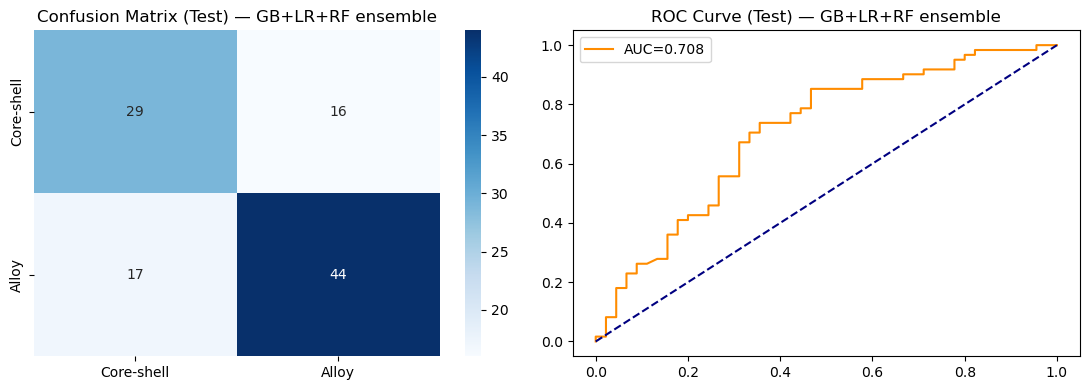

In [9]:
# سلول ۹: ارزیابی نهایی با مدل منتخب
final_model.fit(X_train_raw, y_train)
p_final = final_model.predict_proba(X_test_raw)[:, 1]
pred = (p_final >= 0.5).astype(int)

accuracy = accuracy_score(y_test, pred)
precision = precision_score(y_test, pred, zero_division=0)
recall = recall_score(y_test, pred, zero_division=0)
f1 = f1_score(y_test, pred, zero_division=0)
roc_auc = roc_auc_score(y_test, p_final)
baseline = max(y_test.mean(), 1 - y_test.mean())

print(f'مدل نهایی: {best_name}')
print('عملکرد نهایی روی Test:')
print(f'Accuracy : {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall   : {recall:.4f}')
print(f'F1-score : {f1:.4f}')
print(f'ROC-AUC  : {roc_auc:.4f}')
print(f'Baseline : {baseline:.4f}')
print()
print(classification_report(y_test, pred, target_names=['Core-shell', 'Alloy'], zero_division=0))

cm = confusion_matrix(y_test, pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Core-shell','Alloy'], yticklabels=['Core-shell','Alloy'], ax=axes[0])
axes[0].set_title(f'Confusion Matrix (Test) — {best_name}')
fpr, tpr, _ = roc_curve(y_test, p_final)
axes[1].plot(fpr, tpr, label=f'AUC={roc_auc:.3f}', color='darkorange')
axes[1].plot([0,1],[0,1],'--', color='navy')
axes[1].set_title(f'ROC Curve (Test) — {best_name}')
axes[1].legend()
plt.tight_layout(); plt.show()


## گام ۹: اهمیت فیچرها
با فلزات دقیق‌تر، فیچر شیمیایی `RedPot_Avg` حالا **مهم‌ترین فیچر مدل** شده — این تایید می‌کنه که دقیق‌تر کردن نام فلزات، به مدل کمک کرد از شیمی واقعی بهتر استفاده کنه.


تعداد فیچر انتخاب‌شده: 26 از 85
                              Feature  Importance
                           RedPot_Avg    0.154394
                Incubation_Time (min)    0.131508
          Incubation_Temperature (°C)    0.087998
                          RedPot_Diff    0.085526
        Precursor_2_Concentration (M)    0.076666
        Precursor_1_Concentration (M)    0.075511
                 Stirring_Speed (rpm)    0.074869
                               Has_Fe    0.071867
                                   pH    0.055899
Precursor_1_Concentration (M)_missing    0.044653
                  Concentration_Ratio    0.025595
                  Total_Concentration    0.021635
             Concentration_Difference    0.017073
                          Metal_2__Au    0.013372
Precursor_2_Concentration (M)_missing    0.013044


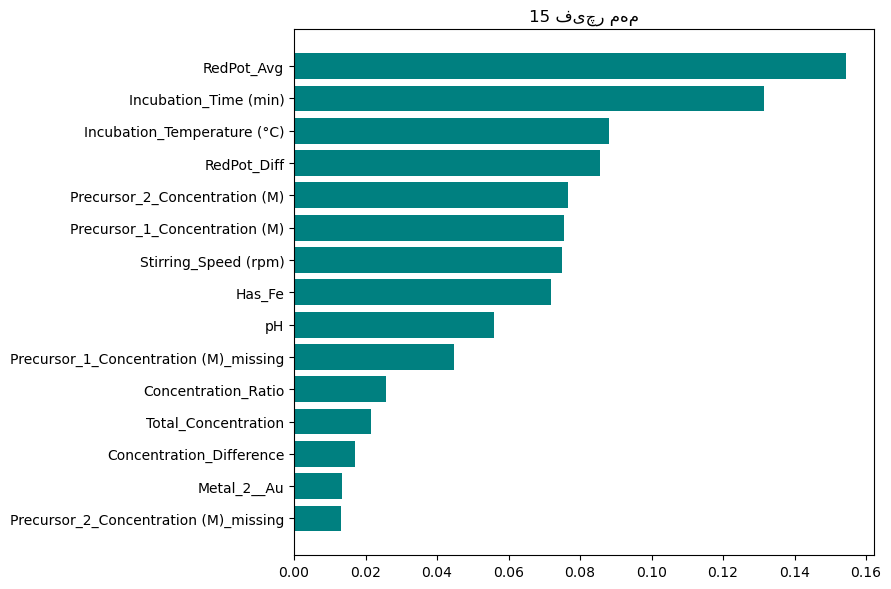

In [10]:
# سلول ۱۰: Feature Importance
fe = best_gb.named_steps['features']; fe.fit(X_train_raw)
names = fe.transform(X_train_raw).columns.to_numpy()
support = best_gb.named_steps['selector'].get_support()
sel_names = names[support]
imp = best_gb.named_steps['clf'].feature_importances_
imp_df = pd.DataFrame({'Feature': sel_names, 'Importance': imp}).sort_values('Importance', ascending=False)
print(f"\u062a\u0639\u062f\u0627\u062f \u0641\u06cc\u0686\u0631 \u0627\u0646\u062a\u062e\u0627\u0628‌\u0634\u062f\u0647: {len(sel_names)} \u0627\u0632 {len(names)}")
print(imp_df.head(15).to_string(index=False))

plt.figure(figsize=(9,6))
top15 = imp_df.head(15)
plt.barh(top15['Feature'][::-1], top15['Importance'][::-1], color='teal')
plt.title('15 \u0641\u06cc\u0686\u0631 \u0645\u0647\u0645')
plt.tight_layout(); plt.show()


## ⚠️ گام ۱۰: بررسی ریسک Overfitting روی ترکیب‌های فلزی کم‌نمونه
با دقیق‌تر شدن نام فلزات، تعداد دسته‌بندی از ۳۸ به ۶۴ رسید. بررسی کردیم که آیا مدل داره روی ترکیب‌های خیلی کم‌نمونه (مثلاً فقط ۱ نمونه) بیش‌ازحد مطمئن می‌شه یا نه — این خیلی مهمه چون مستقیماً روی قابل‌اعتماد بودن پیشنهادهای نهایی تاثیر می‌ذاره.


In [11]:
# سلول ۱۱: بررسی پراکندگی نمونه در هر ترکیب فلزی
metal_counts = X_raw['Bimetallic_NP_Type'].value_counts()
print(f"\u062a\u0639\u062f\u0627\u062f \u06a9\u0644 \u062a\u0631\u06a9\u06cc\u0628 \u0641\u0644\u0632\u06cc: {len(metal_counts)}")
print(f"\u062a\u0631\u06a9\u06cc\u0628\u200c\u0647\u0627\u06cc\u06cc \u06a9\u0647 \u0641\u0642\u0637 ۱-۳ \u0646\u0645\u0648\u0646\u0647 \u062f\u0627\u0631\u0646: {(metal_counts<=3).sum()}")
print()
print("\u0646\u0645\u0648\u0646\u0647: \u062a\u0631\u06a9\u06cc\u0628\u200c\u0647\u0627\u06cc \u06a9\u0645-\u0646\u0645\u0648\u0646\u0647:")
print(metal_counts[metal_counts<=3].head(10))
print()
print("\u26A0\uFE0F \u0628\u0631\u0627\u06cc \u062a\u0648\u0644\u06cc\u062f \u06a9\u0627\u0646\u062f\u06cc\u062f\u0627\u0647\u0627 (\u0633\u0644\u0648\u0644 \u0628\u0639\u062f\u06cc)\u060c \u0641\u0642\u0637 \u0627\u0632 \u062a\u0631\u06a9\u06cc\u0628\u200c\u0647\u0627\u06cc\u06cc \u0628\u0627 \u062d\u062f\u0627\u0642\u0644 ۸ \u0646\u0645\u0648\u0646\u0647 \u0648\u0627\u0642\u0639\u06cc \u0627\u0633\u062a\u0641\u0627\u062f\u0647 \u0645\u06cc\u200c\u06a9\u0646\u06cc\u0645 \u062a\u0627 \u0627\u0632 \u0627\u0639\u062a\u0645\u0627\u062f \u0628\u06cc\u0634\u200c\u0627\u0632\u062d\u062f \u0628\u0647 \u06cc\u06a9 \u06cc\u0627 \u062f\u0648 \u0646\u0645\u0648\u0646\u0647\u200c\u06cc \u0646\u0627\u062f\u0631 \u062c\u0644\u0648\u06af\u06cc\u0631\u06cc \u0634\u0648\u062f.")


تعداد کل ترکیب فلزی: 64
ترکیب‌هایی که فقط ۱-۳ نمونه دارن: 35

نمونه: ترکیب‌های کم-نمونه:
Bimetallic_NP_Type
Au-Cu       3
Ni-Co       2
Fe-Ca       2
Cu-Pd       2
Cu-Mn       2
Ag-based    2
Au-Zn       2
Au-Se       2
Ag-Bi       2
Ag-Mn       1
Name: count, dtype: int64

⚠️ برای تولید کاندیداها (سلول بعدی)، فقط از ترکیب‌هایی با حداقل ۸ نمونه واقعی استفاده می‌کنیم تا از اعتماد بیش‌ازحد به یک یا دو نمونه‌ی نادر جلوگیری شود.


## گام ۱۱: مدل «تولید» نهایی — آموزش روی ۱۰۰٪ داده


In [12]:
# سلول ۱۲: بازآموزی روی کل داده + ذخیره
final_model.fit(X_raw, y)
joblib.dump(final_model, 'alloy_predictor_final.joblib')
print(f'\u2705 \u0645\u062f\u0644 \u0631\u0648\u06cc \u06a9\u0644 \u062f\u0627\u062f\u0647 ({X_raw.shape[0]} \u0646\u0645\u0648\u0646\u0647) \u0628\u0627\u0632\u0622\u0645\u0648\u0632\u06cc \u0634\u062f')


✅ مدل روی کل داده (529 نمونه) بازآموزی شد


## گام ۱۲: پیشنهاد ۱۰ شرایط آزمایشگاهی (فقط از ترکیب‌های فلزی قابل‌اعتماد)
طبق بررسی گام ۱۰، فقط ترکیب‌های فلزی با **حداقل ۸ نمونه‌ی واقعی** در جست‌وجوی کاندیدها استفاده می‌شن — تا پیشنهادها از الگوهای واقعی و تکرارشده بیان، نه از حفظ‌کردن یک نمونه‌ی تصادفی.


In [14]:
# سلول ۱۳: تولید و رتبه‌بندی کاندیدها
reliable_metals = metal_counts[metal_counts >= 8].index.tolist()
print(f"\u062a\u0631\u06a9\u06cc\u0628\u200c\u0647\u0627\u06cc \u0642\u0627\u0628\u0644\u200c\u0627\u0639\u062a\u0645\u0627\u062f: {reliable_metals}")

route_agent_pairs = X_raw.dropna(subset=['Synthesis_Route','Producing_Agent'])[['Synthesis_Route','Producing_Agent']]
route_agent_choices = route_agent_pairs.drop_duplicates().values.tolist()

rng = np.random.RandomState(11)
N = 3000
rows = []
for i in range(N):
    metal = rng.choice(reliable_metals)
    synth, agent = route_agent_choices[rng.randint(0, len(route_agent_choices))]
    c1 = np.exp(rng.uniform(np.log(0.001), np.log(0.005)))
    c2 = c1 * rng.uniform(0.9, 1.1)
    temp = rng.uniform(25, 80)
    time_ = rng.uniform(10, 120)
    ph = rng.uniform(6.0, 9.0)
    stir = rng.choice([300, 300, 300, 400, 500])
    rows.append({
        'Bimetallic_NP_Type': metal, 'Synthesis_Route': synth, 'Precursor_1': 'NA', 'Precursor_2': 'NA',
        'Precursor_1_Concentration (M)': c1, 'Precursor_2_Concentration (M)': c2,
        'Producing_Agent': agent, 'Incubation_Temperature (\u00b0C)': temp,
        'Incubation_Time (min)': time_, 'pH': ph, 'Stirring_Speed (rpm)': stir
    })
cand_df = pd.DataFrame(rows)
p_cand = final_model.predict_proba(cand_df)[:,1]
cand_df['Alloy_Probability'] = p_cand.round(4)
cand_df['Conc_Ratio'] = (cand_df['Precursor_1_Concentration (M)']/cand_df['Precursor_2_Concentration (M)']).round(3)

top10 = cand_df.sort_values('Alloy_Probability', ascending=False).head(10).reset_index(drop=True)
top10.insert(0, 'Rank', range(1, 11))
display_cols = ['Rank', 'Synthesis_Route', 'Producing_Agent',
                 'Precursor_1_Concentration (M)', 'Precursor_2_Concentration (M)', 'Conc_Ratio',
                 'Incubation_Temperature (\u00b0C)', 'Incubation_Time (min)', 'pH', 'Stirring_Speed (rpm)',
                 'Alloy_Probability']
final_table = top10[display_cols]
final_table


ترکیب‌های قابل‌اعتماد: ['Ag-Au', 'Ag-Fe', 'Ag-Cu', 'Ag-Fe3O4', 'Au-Pd', 'Ag-ZnO', 'Cu-Fe', 'Ag-Fe2O3', 'Ag-Pd', 'Fe-Ni', 'Cu-Ni', 'Au-Pt', 'Ag-Ni', 'Zn-Mg', 'Cu-Zn', 'CuO-ZnO', 'Fe-Zn']


,Rank,Synthesis_Route,Producing_Agent,Precursor_1_Concentration (M),Precursor_2_Concentration (M),Conc_Ratio,Incubation_Temperature (°C),Incubation_Time (min),pH,Stirring_Speed (rpm),Alloy_Probability
0,1,Biological,Inorganic molecule,0.002495,0.002487,1.003,58.354227,112.706959,7.914436,300,0.8919
1,2,Biological,Biopolymer,0.002381,0.002506,0.950,53.330429,98.386093,8.906128,300,0.8919
2,3,Biological,Inorganic molecule,0.001060,0.000963,1.101,64.710497,91.886828,8.370722,300,0.8908
3,4,Biological,Inorganic molecule,0.001226,0.001302,0.942,59.395680,79.820934,8.698976,300,0.8905
4,5,Biological,Biopolymer,0.001113,0.001048,1.062,63.966112,113.852799,7.802670,300,0.8902
5,6,Biological,Inorganic molecule,0.001156,0.001227,0.942,61.723179,77.753893,8.591296,300,0.8896
6,7,Biological,Biopolymer,0.002572,0.002370,1.085,44.962730,56.247662,7.962998,300,0.8877
7,8,Biological,Inorganic molecule,0.001316,0.001420,0.927,53.653242,56.787519,8.580257,300,0.8871
8,9,Biological,Biopolymer,0.001390,0.001409,0.987,43.937457,113.159709,7.784596,300,0.8870
9,10,Biological,Microorganism,0.001464,0.001550,0.945,70.953172,81.921470,8.531873,300,0.8863


---
## بخش تکمیلی: نمودارهای بصری اضافی
این بخش چند نمودار برای درک بهتر داده و مقایسه‌ی مدل‌ها اضافه می‌کنه. عنوان‌ها و برچسب‌های داخل نمودارها انگلیسی نوشته شدن چون matplotlib از راست‌به‌چپ فارسی پشتیبانی نمی‌کنه و متن فارسی داخل نمودار به‌هم‌ریخته نمایش داده می‌شه؛ توضیحات فارسی همینجا بالای هر نمودار اومده.

### نمودار ۱: پراکندگی مقادیر گمشده در متغیرهای عددی

In [ ]:
# پراکندگی مقادیر گمشده
cols_disp = ['pH','Precursor_2_Concentration (M)','Precursor_1_Concentration (M)',
             'Incubation_Time (min)','Incubation_Temperature (\u00b0C)','Stirring_Speed (rpm)']
missing_pct = (X_raw[cols_disp].isna().sum()/len(X_raw)*100).sort_values(ascending=True)

plt.figure(figsize=(8,5))
missing_pct.plot(kind='barh', color='indianred')
plt.xlabel('Missing values (%)')
plt.title('Missing Value Prevalence by Variable')
plt.tight_layout()
plt.show()

### نمودار ۲: پراکندگی متغیرهای عددی به تفکیک کلاس هدف (Alloy در مقابل Core-shell)

In [ ]:
# Boxplot پراکندگی هر متغیر عددی، جدا برای Alloy و Core-shell
numeric_cols = ['Precursor_1_Concentration (M)','Precursor_2_Concentration (M)',
                'Incubation_Temperature (\u00b0C)','Incubation_Time (min)','pH','Stirring_Speed (rpm)']
plot_df = X_raw[numeric_cols].copy()
plot_df['NP_Structure'] = y.map({1:'Alloy', 0:'Core-shell'}).values

fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=plot_df, x='NP_Structure', y=col, ax=ax, hue='NP_Structure',
                palette=['#4C72B0','#DD8452'], legend=False)
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Distribution of Numeric Variables by Structure Class', y=1.02)
plt.tight_layout()
plt.show()

### نمودار ۳: نقشه‌ی حرارتی همبستگی متغیرهای عددی

In [ ]:
# Correlation Heatmap
corr_df = X_raw[numeric_cols].apply(pd.to_numeric, errors='coerce')
corr_df['NP_Structure'] = y.values
corr = corr_df.dropna().corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.show()

### نمودار ۴: مقایسه‌ی بصری الگوریتم‌ها (بر اساس Cross-Validation)

In [ ]:
# مقایسه ستونی ۶ الگوریتم (ROC-AUC و Accuracy)
results_viz = {}
for name, pipe in model_zoo.items():
    auc = cross_val_score(pipe, X_train_raw, y_train, cv=cv5, scoring='roc_auc', n_jobs=1)
    acc = cross_val_score(pipe, X_train_raw, y_train, cv=cv5, scoring='accuracy', n_jobs=1)
    results_viz[name] = {'ROC-AUC': auc.mean(), 'Accuracy': acc.mean()}

res_df = pd.DataFrame(results_viz).T.sort_values('ROC-AUC', ascending=False)
ax = res_df.plot(kind='bar', figsize=(9,5), color=['#4C72B0','#55A868'])
plt.ylabel('Score')
plt.title('Algorithm Comparison (5-fold Cross-Validation)')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### نمودار ۵ (جدول هات‌اسپات): نرخ Alloy به تفکیک روش سنتز و عامل تولید

In [ ]:
# Heatmap نرخ Alloy بر اساس ترکیب روش سنتز x عامل تولید
pivot_df = X_raw[['Synthesis_Route','Producing_Agent']].copy()
pivot_df['NP_Structure'] = y.values
pivot = pivot_df.pivot_table(index='Producing_Agent', columns='Synthesis_Route',
                              values='NP_Structure', aggfunc='mean')

plt.figure(figsize=(6,5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu', cbar_kws={'label': 'Alloy rate'})
plt.title('Alloy Formation Rate by Route and Producing Agent')
plt.tight_layout()
plt.show()

### نمودار ۶ (جدول هات‌اسپات): نرخ Alloy به تفکیک ترکیب فلزی (فقط ترکیب‌های قابل‌اعتماد)

In [ ]:
# Heatmap نرخ Alloy برای ترکیب‌های فلزی با حداقل ۸ نمونه
metal_pivot_df = X_raw[['Bimetallic_NP_Type']].copy()
metal_pivot_df['NP_Structure'] = y.values
metal_counts_viz = X_raw['Bimetallic_NP_Type'].value_counts()
reliable_for_viz = metal_counts_viz[metal_counts_viz >= 8].index.tolist()
metal_pivot_df = metal_pivot_df[metal_pivot_df['Bimetallic_NP_Type'].isin(reliable_for_viz)]
metal_rate = metal_pivot_df.groupby('Bimetallic_NP_Type')['NP_Structure'].agg(['mean','count']).sort_values('mean', ascending=False)

plt.figure(figsize=(6, max(4, 0.4*len(metal_rate))))
sns.heatmap(metal_rate[['mean']], annot=metal_rate[['mean','count']].apply(
    lambda r: f"{r['mean']:.2f}\n(n={int(r['count'])})", axis=1).values.reshape(-1,1),
    fmt='', cmap='YlOrRd', cbar_kws={'label': 'Alloy rate'}, yticklabels=metal_rate.index)
plt.title('Alloy Formation Rate by Reliable Composition (n\u22658)')
plt.xlabel(''); plt.xticks([])
plt.tight_layout()
plt.show()